In [ ]:
# Exercise 2.5

import random
from torch.distributions import Normal
import torch

"""

Exercise 2.5 (programming) Design and conduct an experiment to demonstrate the difficulties that sample-average methods have for nonstationary problems.
Use a modified version of the 10-armed testbed in which all the q⇤(a) start out equal and then take independent random walks
(say by adding a normally distributed increment with mean 0 and standard deviation 0.01 to all the q⇤(a) on each step).
Prepare plots like Figure 2.2 for an action-value method using sample averages, incrementally computed, and another action-value method using a constant step-size parameter,
alpha=0.1. Use epsilon=0.1 and longer runs, say of 10,000 steps.

"""

arms = arms = torch.full((10,), 100.0)
print(arms)
q_value = [10] * 10
q_non = [10] * 10

print(q_value)

NUM_STEPS = 10000
EPSILON = 0.1
ALPHA = 0.1

action_history = []
norm = [0] * 10
norm_non = norm
total_reward = 0
total_reward_non = 0
action = 0

log_stationary = []
log_non_stationary = []

#Simple bandit
for i in range(NUM_STEPS):

  rand = random.random()

  if(EPSILON > rand):
    action = random.randint(0,9)
    action_non = action
  else:
    action = max(enumerate(q_value), key=lambda x: x[1])[0]
    action_non = max(enumerate(q_non), key=lambda x: x[1])[0]

  #Stationary Assumption:
  rew = Normal(loc=arms[action], scale = 1).sample()
  total_reward += rew.item()
  action_history.append((action, q_value, rew))
  norm[action] += 1

  q_value[action] = q_value[action] + (rew.item() - q_value[action])/norm[action]

  #Non-Stationary Assumption:
  rew_non = Normal(loc=arms[action_non], scale = 1).sample()
  total_reward_non += rew_non.item()
  action_history.append((action_non, q_non, rew_non))
  #norm_non[action] += 1

  q_non[action_non] += ALPHA*(rew_non.item() - q_non[action_non])

  #Log for plotting
  log_stationary.append((action, q_value, rew, i, total_reward, arms))
  log_non_stationary.append((action_non, q_non, rew_non, i, total_reward_non, arms))

  #Move the arms
  means = torch.zeros(10)
  std_devs = torch.full((10, ), 0.01)
  walk_dist = Normal(loc=means, scale=std_devs)
  noise = walk_dist.sample()
  #print(arms)
  #break
  arms = arms + noise
  #print(arms)
  #break


print(arms)
print(q_value)
print(q_non)



tensor([100., 100., 100., 100., 100., 100., 100., 100., 100., 100.])
[10, 10, 10, 10, 10, 10, 10, 10, 10, 10]
tensor([101.1193,  98.8613,  99.7976,  99.2819,  99.5439,  99.8502, 100.7641,
         98.2173, 100.3568,  99.5362])
[100.34162750244136, 99.11764495849607, 101.09107141532797, 99.17332548253677, 100.44654754853597, 100.00955109202533, 100.11225494136656, 99.03522133827211, 99.96961656588954, 99.76610938538897]
[100.88574254779267, 98.81031852949076, 100.17991643944003, 98.63648583686826, 99.00762563017315, 99.6305111245219, 100.08663154155673, 98.52997934785483, 100.2727129625512, 99.33084393027934]


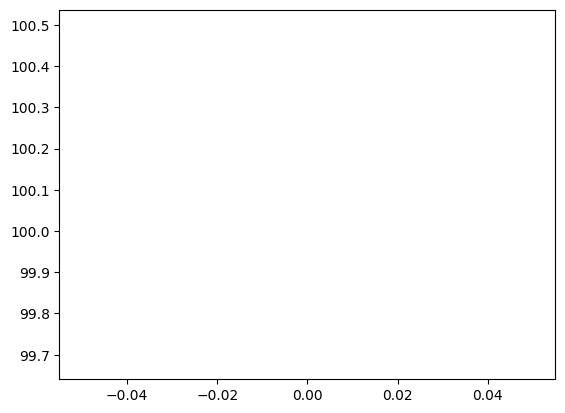

In [ ]:
#plot
import matplotlib.pyplot as plt
import numpy as np

from matplotlib.collections import EventCollection

fig = plt.figure()
ax = fig.add_subplot(1, 1, 1)

x_stationary = [row[3] for row in log_stationary]
y_stationary = [row[4]/(row[3]+1) for row in log_stationary]


x_non_stationary = [row[3] for row in log_non_stationary]
y_non_stationary = [row[4]/(row[3]+1) for row in log_non_stationary]



ax.plot(x_stationary, y_stationary, color='tab:blue')
ax.plot(x_non_stationary, y_non_stationary, color='tab:orange')